# 02 · Análisis exploratorio (EDA) de los historiales

Proyecto «Playlist perfecta para viajes en grupo» · NPD Entertainment · CEBANC · Ander Ameztoy

Qué responde este notebook, en el orden del informe v2:

1. Cuánto y cuándo escucha cada miembro.
2. Cómo terminan las reproducciones y por qué la tasa de no salto usa el salto rápido (`fwdbtn` < 30 s).
3. Cómo se reparte la `tasa_no_salto` por persona × canción × contexto (la variable objetivo del objetivo 1) y cuántas filas tiene la tabla gold.
4. Si el contexto (franja × tipo de día) cambia la tasa.
5. Cuánto se parecen los gustos del grupo (canciones y artistas en común).
6. Cómo quedan los lotes 1 y 2 con el corte del 1 de julio de 2025, y si en el lote 2 hay canciones suficientes para evaluar playlists de N = 20, 50 y 100.

**Privacidad.** Del historial solo se leen los campos de `CAMPOS`; `ip_addr`, `conn_country` y el resto se descartan al leer. Las salidas son cifras agregadas y gráficos, nunca filas del historial.

Uso de IA (nivel VERDE): notebook escrito con ayuda de Claude y revisado por Ander.

## 0. Configuración

In [1]:
from pathlib import Path
import glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/proyecto-Ebaluacion1")
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Historiales originales: data/raw/<persona>/ (entrada de pipeline.sh); en Drive y en instalaciones
# antiguas están en data/entrada/historial/<persona>/
CARPETA_HISTORIAL = RAIZ / "data" / "raw"
if not (CARPETA_HISTORIAL / "ander").exists():
    CARPETA_HISTORIAL = RAIZ / "data" / "entrada" / "historial"
HISTORIALES = {
    "ander":  CARPETA_HISTORIAL / "ander",
    "daniel": CARPETA_HISTORIAL / "daniel",
}
CAMPOS = ["ts", "ms_played", "spotify_track_uri", "master_metadata_track_name",
          "master_metadata_album_artist_name", "reason_end", "shuffle", "platform"]

ZONA = "Europe/Madrid"
CORTE = pd.Timestamp("2025-07-01", tz=ZONA)     # lote 1 < corte <= lote 2 (sección 9.1 del informe)
MIN_ESCUCHAS = 5                                # filas gold fiables
UMBRAL_SALTO_MS = 30_000                        # salto rápido = fwdbtn antes de 30 s
N_PLAYLIST = [20, 50, 100]                      # N principal = 50; 20 y 100 de sensibilidad

# Paleta del proyecto: Ander verde, Daniel rojo (como en el Gantt)
COLOR = {"ander": "#56BE91", "daniel": "#FD3B1F"}
NEGRO, GRIS = "#020202", "#B9B6AE"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlelocation": "left"})

FIGURAS = RAIZ / "notebooks" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
SALIDA = RAIZ / "data" / "salida"
SALIDA.mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png", dpi=200, bbox_inches="tight")

print("Entorno:", "Google Colab" if EN_COLAB else "local", "| raíz:", RAIZ)

Mounted at /content/drive
Entorno: Google Colab | raíz: /content/drive/MyDrive/proyecto-Ebaluacion1


## 1. Carga y variables de contexto

In [2]:
def leer(carpeta, persona):
    ficheros = sorted(set(glob.glob(str(carpeta / "**" / "Streaming_History_Audio_*.json"), recursive=True))
                      | set(glob.glob(str(carpeta / "**" / "endsong_*.json"), recursive=True)))
    filas = []
    for f in ficheros:
        with open(f, encoding="utf-8") as fh:
            filas += [{k: r.get(k) for k in CAMPOS} for r in json.load(fh)]   # descarta campos personales
    d = pd.DataFrame(filas, columns=CAMPOS)
    d["persona"] = persona
    return d

h = pd.concat([leer(c, p) for p, c in HISTORIALES.items()], ignore_index=True)
h = h[h["spotify_track_uri"].notna()].copy()                 # solo música
h["track_id"] = h["spotify_track_uri"].str.replace("spotify:track:", "", regex=False)
h["artista"] = h["master_metadata_album_artist_name"]
h["ms_played"] = pd.to_numeric(h["ms_played"])

# Hora local y contexto: 6 franjas de 4 h × tipo de día = 12 contextos
h["hora_local"] = pd.to_datetime(h["ts"], utc=True).dt.tz_convert(ZONA)
FRANJAS = ["madrugada", "primera mañana", "mañana", "mediodía", "tarde", "noche"]   # 0-4, 4-8, 8-12, 12-16, 16-20, 20-24
h["franja"] = pd.Categorical([FRANJAS[x // 4] for x in h["hora_local"].dt.hour], categories=FRANJAS, ordered=True)
h["tipo_dia"] = np.where(h["hora_local"].dt.dayofweek >= 5, "fin de semana", "laborable")
h["lote"] = np.where(h["hora_local"] < CORTE, "lote 1", "lote 2")

# Variable objetivo: salto rápido
h["salto_rapido"] = (h["reason_end"] == "fwdbtn") & (h["ms_played"] < UMBRAL_SALTO_MS)
h["no_salto"] = ~h["salto_rapido"]

resumen = h.groupby("persona").agg(
    reproducciones=("track_id", "size"), canciones=("track_id", "nunique"), artistas=("artista", "nunique"),
    desde=("hora_local", "min"), hasta=("hora_local", "max"),
    horas_escuchadas=("ms_played", lambda s: round(s.sum() / 3.6e6)),
    tasa_no_salto=("no_salto", "mean"))
resumen["desde"] = resumen["desde"].dt.date; resumen["hasta"] = resumen["hasta"].dt.date
resumen["tasa_no_salto"] = resumen["tasa_no_salto"].round(3)
resumen

,reproducciones,canciones,artistas,desde,hasta,horas_escuchadas,tasa_no_salto
persona,,,,,,,
ander,262830,12181,2523,2019-05-10,2026-10-21,4543,0.503
daniel,85473,8362,1636,2020-10-02,2026-11-17,3795,0.927


## 2. Cuánto escucha cada miembro

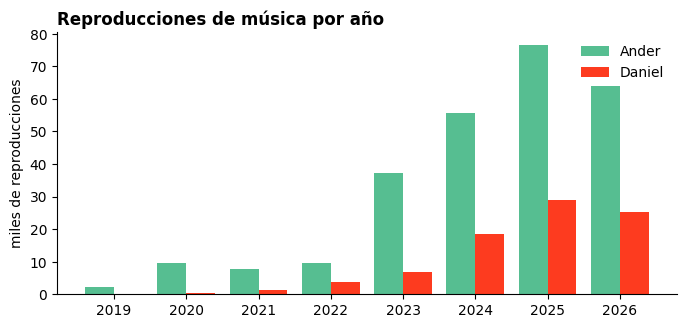

persona,ander,daniel
año,,
2019,2385,0
2020,9682,509
2021,7738,1442
2022,9581,3877
2023,37274,6893
2024,55749,18462
2025,76533,29055
2026,63888,25235


In [3]:
anual = h.groupby([h["hora_local"].dt.year.rename("año"), "persona"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(anual)); w = 0.4
for k, p in enumerate(anual.columns):
    ax.bar(x + (k - 0.5) * w, anual[p] / 1000, w, color=COLOR[p], label=p.capitalize())
ax.set_xticks(x); ax.set_xticklabels(anual.index)
ax.set_ylabel("miles de reproducciones")
ax.set_title("Reproducciones de música por año")
ax.legend(frameon=False)
guardar(fig, "02_reproducciones_por_anyo"); plt.show()
anual

## 3. Cómo terminan las reproducciones

Base de la definición de la variable objetivo: `trackdone` (escucha completa) es minoritario en uno de los dos miembros, y el `fwdbtn` muy temprano es el rechazo claro de una canción.

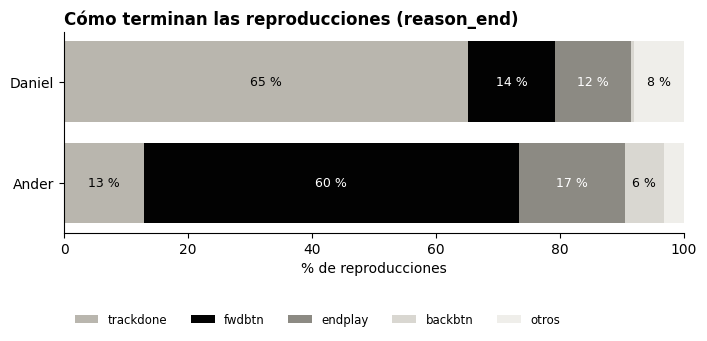

reason_end,trackdone,fwdbtn,endplay,backbtn,otros
persona,,,,,
ander,12.9,60.4,17.2,6.2,3.3
daniel,65.2,13.9,12.4,0.5,8.0


In [4]:
fin = (h.groupby("persona")["reason_end"].value_counts(normalize=True).mul(100).round(1)
         .unstack(fill_value=0))
principales = ["trackdone", "fwdbtn", "endplay", "backbtn"]
fin["otros"] = 100 - fin[principales].sum(axis=1)
fin = fin[principales + ["otros"]]

fig, ax = plt.subplots(figsize=(8, 2.6))
colores = [GRIS, NEGRO, "#8C8A83", "#D9D7D1", "#EFEEEA"]
izq = np.zeros(len(fin))
for c, col in zip(fin.columns, colores):
    ax.barh([p.capitalize() for p in fin.index], fin[c], left=izq, color=col, label=c)
    for i, v in enumerate(fin[c]):
        if v >= 6:
            ax.text(izq[i] + v / 2, i, f"{v:.0f} %", ha="center", va="center",
                    color="white" if col in (NEGRO, "#8C8A83") else NEGRO, fontsize=9)
    izq += fin[c].to_numpy()
ax.set_xlim(0, 100); ax.set_xlabel("% de reproducciones")
ax.set_title("Cómo terminan las reproducciones (reason_end)")
ax.legend(ncol=5, frameon=False, bbox_to_anchor=(0, -0.35), loc="upper left", fontsize=8.5)
guardar(fig, "02_reason_end"); plt.show()
fin

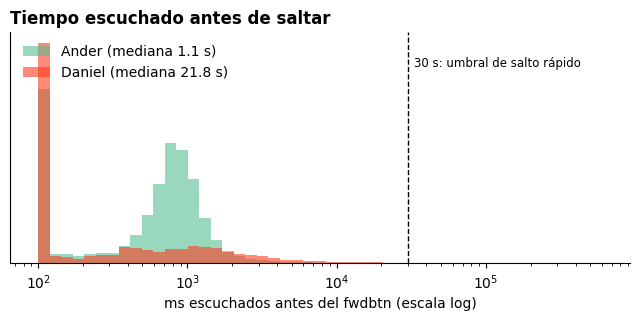

,count,mean,std,min,25%,50%,75%,max
persona,,,,,,,,
ander,158.8,27.0,75.4,0.0,0.8,1.1,3.4,3369.6
daniel,11.9,73.2,88.4,0.0,2.4,21.8,141.8,556.3


In [5]:
# Cuánto se escucha antes de pulsar «siguiente»: casi todo el fwdbtn de un miembro es inmediato
fw = h[h["reason_end"] == "fwdbtn"]
fig, ax = plt.subplots(figsize=(8, 3))
bins = np.logspace(np.log10(100), np.log10(600_000), 50)
for p, d in fw.groupby("persona"):
    ax.hist(d["ms_played"].clip(lower=100), bins=bins, color=COLOR[p], alpha=0.6,
            label=f"{p.capitalize()} (mediana {d['ms_played'].median()/1000:.1f} s)", density=True)
ax.axvline(UMBRAL_SALTO_MS, color=NEGRO, ls="--", lw=1)
ax.text(UMBRAL_SALTO_MS * 1.1, ax.get_ylim()[1] * 0.85, "30 s: umbral de salto rápido", fontsize=8.5)
ax.set_xscale("log"); ax.set_xlabel("ms escuchados antes del fwdbtn (escala log)"); ax.set_yticks([])
ax.set_title("Tiempo escuchado antes de saltar")
ax.legend(frameon=False)
guardar(fig, "02_ms_antes_de_saltar"); plt.show()
fw.groupby("persona")["ms_played"].describe(percentiles=[.25, .5, .75]).div(1000).round(1)

## 4. Variable objetivo: tasa de no salto por persona × canción × contexto

Es la tabla del objetivo 1 (`gold_tasa_no_salto`). Aquí se calcula a partir de los JSON para explorarla; la versión oficial sale de Hive (gold de Daniel). Al final del notebook se comparan las dos.

In [6]:
gold = (h.groupby(["persona", "track_id", "franja", "tipo_dia"], observed=True)
          .agg(escuchas=("no_salto", "size"), tasa_no_salto=("no_salto", "mean"),
               artista=("artista", "first"))
          .reset_index())
fiables = gold[gold["escuchas"] >= MIN_ESCUCHAS]
filas = pd.DataFrame({
    "combinaciones persona × canción × contexto": gold.groupby("persona").size(),
    f"con >= {MIN_ESCUCHAS} escuchas (filas gold)": fiables.groupby("persona").size(),
    "canciones distintas en esas filas": fiables.groupby("persona")["track_id"].nunique(),
    "tasa media": fiables.groupby("persona")["tasa_no_salto"].mean().round(3),
    "tasa mediana": fiables.groupby("persona")["tasa_no_salto"].median().round(3),
    "% de filas con tasa 1": fiables.groupby("persona")["tasa_no_salto"].apply(lambda s: round((s == 1).mean() * 100, 1)),
})
filas.loc["total"] = [len(gold), len(fiables), fiables["track_id"].nunique(), round(fiables["tasa_no_salto"].mean(), 3),
                      round(fiables["tasa_no_salto"].median(), 3), round((fiables["tasa_no_salto"] == 1).mean() * 100, 1)]
filas

,combinaciones persona × canción × contexto,con >= 5 escuchas (filas gold),canciones distintas en esas filas,tasa media,tasa mediana,% de filas con tasa 1
persona,,,,,,
ander,42985.0,14294.0,2419.0,0.504,0.500,4.2
daniel,26849.0,5400.0,1699.0,0.940,1.000,68.7
total,69834.0,19694.0,3833.0,0.624,0.625,21.9


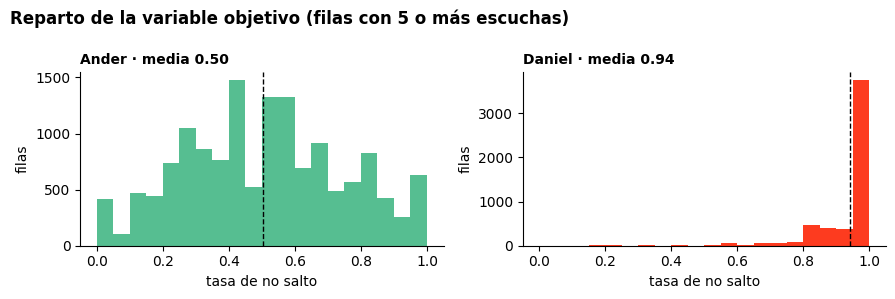

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=False)
for ax, (p, d) in zip(axes, fiables.groupby("persona")):
    ax.hist(d["tasa_no_salto"], bins=np.linspace(0, 1, 21), color=COLOR[p])
    ax.axvline(d["tasa_no_salto"].mean(), color=NEGRO, ls="--", lw=1)
    ax.set_title(f"{p.capitalize()} · media {d['tasa_no_salto'].mean():.2f}", fontsize=10)
    ax.set_xlabel("tasa de no salto"); ax.set_ylabel("filas")
fig.suptitle("Reparto de la variable objetivo (filas con 5 o más escuchas)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "02_reparto_tasa"); plt.show()

In [8]:
# Mismo reparto en percentil: así combina el recomendador a los miembros (decisión de la v1.5).
# Ojo con los empates: si muchas filas tienen tasa 1, todas reciben el mismo percentil (el medio del empate).
fiables = fiables.copy()
fiables["percentil"] = fiables.groupby("persona")["tasa_no_salto"].rank(pct=True)
empates = fiables.groupby("persona").agg(
    filas_con_tasa_1=("tasa_no_salto", lambda s: int((s == 1).sum())),
    percentil_maximo=("percentil", "max"))
empates["percentil_maximo"] = empates["percentil_maximo"].round(2)
empates

,filas_con_tasa_1,percentil_maximo
persona,,
ander,598,0.98
daniel,3710,0.66


## 5. ¿Cambia la tasa según el contexto?

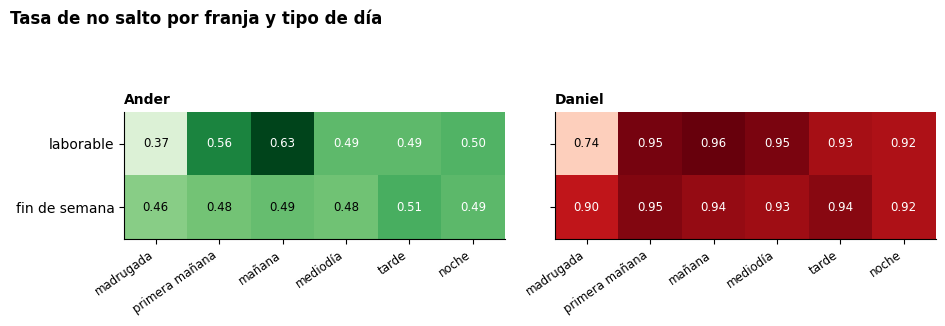

,min,max,diferencia (puntos)
persona,,,
ander,0.370,0.632,26.2
daniel,0.739,0.963,22.4


In [9]:
ctx = (h.groupby(["persona", "tipo_dia", "franja"], observed=True)["no_salto"].agg(["mean", "size"]).reset_index())
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), sharey=True)
for ax, (p, d) in zip(axes, ctx.groupby("persona")):
    tabla = d.pivot(index="tipo_dia", columns="franja", values="mean").reindex(["laborable", "fin de semana"])
    im = ax.imshow(tabla, cmap="Greens" if p == "ander" else "Reds", vmin=tabla.min().min() - 0.05, vmax=tabla.max().max())
    ax.set_xticks(range(len(tabla.columns))); ax.set_xticklabels(tabla.columns, rotation=35, ha="right", fontsize=8.5)
    ax.set_yticks(range(2)); ax.set_yticklabels(tabla.index)
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            v = tabla.iat[i, j]
            if pd.notna(v):
                claro = (v - im.norm.vmin) / (im.norm.vmax - im.norm.vmin) > 0.55
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if claro else NEGRO)
    ax.set_title(p.capitalize(), fontsize=10)
fig.suptitle("Tasa de no salto por franja y tipo de día", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "02_tasa_por_contexto"); plt.show()

rango = ctx.groupby("persona")["mean"].agg(["min", "max"])
rango["diferencia (puntos)"] = ((rango["max"] - rango["min"]) * 100).round(1)
rango.round(3)

In [10]:
# Cuánto se reparten las escuchas entre contextos: un contexto con muy pocas escuchas dará pocas filas gold
reparto_ctx = (h.groupby(["persona", "tipo_dia", "franja"], observed=True).size()
                 .groupby(level=0).transform(lambda s: (s / s.sum() * 100).round(1)).unstack("franja"))
reparto_ctx

franja                 madrugada  primera mañana  mañana  mediodía  tarde  \
persona tipo_dia                                                            
ander   fin de semana        3.7             0.5     3.2       6.9    5.3   
        laborable            5.9             6.1     9.6      19.7   16.7   
daniel  fin de semana        2.6             0.2     2.4       5.4    6.5   
        laborable            6.1             5.2    15.2      20.3   17.0   

franja                 noche  
persona tipo_dia              
ander   fin de semana    6.3  
        laborable       16.1  
daniel  fin de semana    4.4  
        laborable       14.9

## 6. ¿Cuánto se parecen los gustos del grupo?

In [11]:
cancion = {p: set(d["track_id"]) for p, d in h.groupby("persona")}
artista = {p: set(d["artista"].dropna()) for p, d in h.groupby("persona")}
a, b = sorted(cancion)
comun_c, comun_a = cancion[a] & cancion[b], artista[a] & artista[b]
solape = pd.DataFrame({
    "canciones": [len(cancion[a]), len(cancion[b]), len(comun_c), round(len(comun_c) / len(cancion[a] | cancion[b]) * 100, 1)],
    "artistas":  [len(artista[a]), len(artista[b]), len(comun_a), round(len(comun_a) / len(artista[a] | artista[b]) * 100, 1)],
}, index=[a, b, "en común", "% en común (Jaccard)"])

# Peso de lo común en las escuchas de cada uno
for p in (a, b):
    d = h[h["persona"] == p]
    solape.loc[f"% de escuchas de {p} en canciones comunes", "canciones"] = round(d["track_id"].isin(comun_c).mean() * 100, 1)
    solape.loc[f"% de escuchas de {p} en artistas comunes", "artistas"] = round(d["artista"].isin(comun_a).mean() * 100, 1)
solape

,canciones,artistas
ander,12181.0,2523.0
daniel,8362.0,1636.0
en común,2668.0,732.0
% en común (Jaccard),14.9,21.4
% de escuchas de ander en canciones comunes,39.8,NaN
% de escuchas de ander en artistas comunes,NaN,80.3
% de escuchas de daniel en canciones comunes,48.3,NaN
% de escuchas de daniel en artistas comunes,NaN,90.0


In [12]:
top_comunes = (h[h["artista"].isin(comun_a)].groupby(["artista", "persona"]).size().unstack(fill_value=0))
top_comunes["mínimo"] = top_comunes.min(axis=1)
top_comunes.sort_values("mínimo", ascending=False).head(10).drop(columns="mínimo")

persona,ander,daniel
artista,,
Bad Bunny,7041,3866
Myke Towers,2076,3454
Eladio Carrion,3129,1612
Arcángel,1736,1177
Anuel AA,1763,1123
J Balvin,1661,1115
Rauw Alejandro,851,1115
Mora,2437,691
Cruz Cafuné,10603,588


## 7. Lotes 1 y 2 y comprobación de N

Corte temporal el 1 de julio de 2025 (sección 9.1 del informe). Para evaluar la playlist en el lote 2 solo vale la tasa **real** de canciones que sonaron en el lote 2, así que hace falta que haya bastantes más candidatas con tasa real que N.

In [13]:
fiables_l = (h.groupby(["lote", "persona", "track_id", "franja", "tipo_dia"], observed=True)
               .agg(escuchas=("no_salto", "size"), tasa=("no_salto", "mean")).reset_index())
fiables_l = fiables_l[fiables_l["escuchas"] >= MIN_ESCUCHAS]
en_l1 = set(fiables_l.loc[fiables_l["lote"] == "lote 1", "track_id"])
lotes = fiables_l.groupby(["lote", "persona"]).agg(filas=("track_id", "size"), canciones=("track_id", "nunique")).unstack("lote")
l2 = fiables_l[fiables_l["lote"] == "lote 2"]
lotes[("nuevas en el lote 2", "filas")] = l2[~l2["track_id"].isin(en_l1)].groupby("persona").size()
lotes

filas        canciones        nuevas en el lote 2
lote    lote 1 lote 2    lote 1 lote 2               filas
persona                                                   
ander     9094   6978      1538   1582                2773
daniel    2697   1998      1145    985                 973

In [14]:
# Canciones con tasa real en el lote 2 por contexto (5 o más escuchas de al menos un miembro)
cand = (l2.groupby(["tipo_dia", "franja"], observed=True)["track_id"].nunique().unstack("franja"))
print("Canciones con tasa real en el lote 2, por contexto (al menos un miembro):")
display(cand)

# Y con tasa real de LOS DOS miembros en el mismo contexto: las únicas donde el gusto del grupo es real
ambos = (l2.groupby(["tipo_dia", "franja", "track_id"], observed=True)["persona"].nunique().reset_index())
ambos = ambos[ambos["persona"] == 2].groupby(["tipo_dia", "franja"], observed=True).size().unstack("franja")
print("Canciones con tasa real de los dos miembros en el lote 2, por contexto:")
display(ambos)

total_l2 = l2["track_id"].nunique()
max_uno = int(cand.max().max()); max_ambos = int(ambos.max().max())
print(f"En el contexto con más datos del lote 2 hay {max_uno} canciones con tasa real de algún miembro "
      f"y {max_ambos} con tasa real de los dos.")
for n in N_PLAYLIST:
    por_miembro = "sí" if max_uno >= 3 * n else "no"
    por_grupo = "sí" if max_ambos >= 3 * n else "no"
    print(f"N = {n:>3}: evaluable por miembro en un contexto: {por_miembro} | con el gusto real del GRUPO en un contexto: {por_grupo}")

Canciones con tasa real en el lote 2, por contexto (al menos un miembro):


franja,madrugada,primera mañana,mañana,mediodía,tarde,noche
tipo_dia,,,,,,
fin de semana,154,5,125,680,481,376
laborable,607,281,1190,1826,1634,1471


Canciones con tasa real de los dos miembros en el lote 2, por contexto:


franja,madrugada,mañana,mediodía,tarde,noche
tipo_dia,,,,,
fin de semana,NaN,NaN,2.0,4.0,1.0
laborable,7.0,14.0,49.0,34.0,35.0


En el contexto con más datos del lote 2 hay 1826 canciones con tasa real de algún miembro y 49 con tasa real de los dos.
N =  20: evaluable por miembro en un contexto: sí | con el gusto real del GRUPO en un contexto: no
N =  50: evaluable por miembro en un contexto: sí | con el gusto real del GRUPO en un contexto: no
N = 100: evaluable por miembro en un contexto: sí | con el gusto real del GRUPO en un contexto: no


In [15]:
resumen_eda = {
    "filas_gold_total": int(len(fiables)),
    "filas_gold_por_persona": fiables.groupby("persona").size().to_dict(),
    "tasa_media_por_persona": fiables.groupby("persona")["tasa_no_salto"].mean().round(3).to_dict(),
    "canciones_comunes": len(comun_c), "artistas_comunes": len(comun_a),
    "filas_lote2_por_persona": l2.groupby("persona").size().to_dict(),
    "canciones_tasa_real_lote2": int(total_l2),
}
json.dump(resumen_eda, open(SALIDA / "02_resumen_eda.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print(json.dumps(resumen_eda, ensure_ascii=False, indent=1))
print("Figuras guardadas en", FIGURAS)

{
 "filas_gold_total": 19694,
 "filas_gold_por_persona": {
  "ander": 14294,
  "daniel": 5400
 },
 "tasa_media_por_persona": {
  "ander": 0.504,
  "daniel": 0.94
 },
 "canciones_comunes": 2668,
 "artistas_comunes": 732,
 "filas_lote2_por_persona": {
  "ander": 6978,
  "daniel": 1998
 },
 "canciones_tasa_real_lote2": 2469
}
Figuras guardadas en /content/drive/MyDrive/proyecto-Ebaluacion1/notebooks/figuras


## 8. Comparación con el gold de Hive

El pipeline exporta `gold.objetivo1` a `data/dataset/gold_objetivo1.csv` (`bigdata/exportar.py`; se comparte por Drive, no por Git). Aquí se comprueba que el cálculo de este notebook, hecho sobre los JSON originales, coincide con el de Hive, hecho sobre `silver.reproducciones`.

Hay que comparar lo mismo con lo mismo:

- Las **19.694 filas fiables** de la sección 4 juntan todo el historial: una fila por persona × canción × contexto, **sin separar por lote**.
- Las **19.927 filas fiables** de Hive son por persona × canción × contexto **× lote**. La cifra comparable de este notebook es la de `fiables_l` (sección 7): 9.094 + 6.978 + 2.697 + 1.998 = **20.767**.

Los seudónimos de Hive (`persona_<hash>`) se emparejan con los nombres por las canciones que comparten, sin usar ningún dato personal.

In [16]:
ruta_gold = RAIZ / "data" / "dataset" / "gold_objetivo1.csv"
if not ruta_gold.exists():
    print(f"No está {ruta_gold}: cópialo desde Drive (lo genera bigdata/exportar.py en pipeline.sh).")
    gh = None
else:
    gh = pd.read_csv(ruta_gold, encoding="utf-8-sig", dtype={"track_id": str})
    gh = gh[gh["fiable"] == 1].copy()
    print(f"Gold de Hive: {len(gh):,} filas fiables".replace(",", "."))

    # Mismas claves que el notebook: franja con nombre, tipo de día como en la sección 1 y lote como texto
    TIPO_DIA_NB = {"laborable": "laborable", "fin_semana": "fin de semana"}
    gh["franja"] = gh["franja"].map(dict(enumerate(FRANJAS)))
    gh["tipo_dia"] = gh["tipo_dia"].map(TIPO_DIA_NB)
    gh["lote"] = "lote " + gh["lote"].astype(str)

    # Seudónimo de Hive -> nombre: el que más canciones comparte
    canciones_nb = {p: set(d["track_id"]) for p, d in fiables_l.groupby("persona")}
    pareja = {}
    for seud, d in gh.groupby("persona"):
        t = set(d["track_id"])
        pareja[seud] = max(canciones_nb, key=lambda p: len(t & canciones_nb[p]) / len(t | canciones_nb[p]))
    gh["persona"] = gh["persona"].map(pareja)
    print("Seudónimos:", pareja)

    claves = ["lote", "persona", "track_id", "franja", "tipo_dia"]
    nb_l = fiables_l.assign(franja=fiables_l["franja"].astype(str))[claves + ["escuchas", "tasa"]]
    cruce = nb_l.merge(gh[claves + ["n_escuchas", "tasa_no_salto"]], on=claves, how="outer", indicator=True)

    resumen_cmp = (cruce.groupby(["persona", "lote", "_merge"], observed=True).size()
                        .unstack("_merge").reindex(columns=["both", "left_only", "right_only"]).fillna(0).astype(int)
                        .rename(columns={"both": "en los dos", "left_only": "solo notebook", "right_only": "solo Hive"}))
    resumen_cmp.loc[("total", ""), :] = resumen_cmp.sum()
    resumen_cmp = resumen_cmp.astype(int)
    display(resumen_cmp)

    ambos = cruce[cruce["_merge"] == "both"]
    dif_esc = ambos["escuchas"] - ambos["n_escuchas"]
    dif_tasa = (ambos["tasa"] - ambos["tasa_no_salto"]).abs()
    print(f"Filas fiables: notebook por lote {len(nb_l):,} | Hive {len(gh):,} | sin separar por lote {len(fiables):,}"
          .replace(",", "."))
    print(f"En las {len(ambos):,} filas comunes:".replace(",", "."),
          f"mismas escuchas en el {(dif_esc == 0).mean():.1%};",
          f"el notebook cuenta más escuchas en el {(dif_esc > 0).mean():.1%} (de media {dif_esc[dif_esc > 0].mean():.1f} más);",
          f"diferencia media de tasa {dif_tasa.mean():.4f} (máxima {dif_tasa.max():.3f}).")


Gold de Hive: 19.927 filas fiables
Seudónimos: {'persona_358ed916': 'daniel', 'persona_744b89e7': 'ander'}


_merge          en los dos  solo notebook  solo Hive
persona lote                                        
ander   lote 1        8738            356          0
        lote 2        6720            258          0
daniel  lote 1        2581            116          0
        lote 2        1888            110          0
total                19927            840          0

Filas fiables: notebook por lote 20.767 | Hive 19.927 | sin separar por lote 19.694
En las 19.927 filas comunes: mismas escuchas en el 67.5%; el notebook cuenta más escuchas en el 32.5% (de media 1.8 más); diferencia media de tasa 0.0128 (máxima 0.556).


**Lectura (ejecución del 25 de noviembre).** Las **19.927 filas fiables del gold de Hive están todas en el cálculo de este notebook**, con las mismas claves (persona, canción, franja, tipo de día y lote); ninguna está solo en Hive. El notebook tiene **840 filas fiables más** (20.767 en total): combinaciones que llegan a 5 escuchas con los JSON originales y se quedan por debajo en Hive, porque `silver.reproducciones` quita los duplicados (en bronze había 12.044, parte de la propia exportación de Spotify) y las reproducciones de 0 ms o negativas (sección 12.8 del informe). Por el mismo motivo, en el 32,5 % de las filas comunes el notebook cuenta más escuchas (1,8 de media), y la tasa de no salto cambia muy poco: 0,013 de media.

Las 19.694 filas de la sección 4 no se pueden comparar con las 19.927 porque juntan los dos lotes. Los modelos se entrenan con el gold de Hive, que es el dataset curado que entrega la parte de Big Data; este notebook solo sirve para explorar.